# Bab 7: Support Vector Machines and Kernel Methods

Notebook ini merangkum Bab 7 buku *scikit-learn Cookbook* (Third Edition) karya John Sukup. Sampai bab sebelumnya, dataset yang dipakai relatif mudah dipisahkan. Data nyata jarang begitu, jadi kita butuh alat untuk kasus ketika batas antar kelas tidak bisa digambar dengan garis lurus. Support vector machine (SVM) dan kernel adalah salah satu jawabannya.

Isi notebook:

1. Pengantar SVM
2. Fungsi kernel dan penerapannya
3. Tuning parameter SVM
4. SVM pada ruang berdimensi tinggi
5. Evaluasi model SVM
6. Latihan praktik

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_iris, load_breast_cancer, make_classification, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, SVR
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, classification_report,
                             mean_squared_error, roc_curve, auc)

pd.set_option("display.precision", 4)


def styled_report(y_true, y_pred, **kwargs):
    """Classification report sebagai DataFrame berwarna."""
    rep = pd.DataFrame(classification_report(y_true, y_pred, output_dict=True, **kwargs)).transpose()
    return (rep.style
            .background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"])
            .format({"precision": "{:.3f}", "recall": "{:.3f}",
                     "f1-score": "{:.3f}", "support": "{:.0f}"}))

## 1. Introduction to SVMs

SVM bisa dipakai untuk klasifikasi maupun regresi. Metode ini efektif ketika jumlah fitur besar dibanding jumlah sampel, atau saat kelas tidak mudah dipisahkan dengan fitur aslinya.

Ide intinya: cari **hyperplane** yang memaksimalkan **margin** antar kelas.

> **Hyperplane**: batas keputusan yang membagi ruang fitur menjadi wilayah-wilayah untuk tiap kelas. Pada dua dimensi bentuknya garis, pada tiga dimensi bentuknya bidang.
>
> **Margin**: jarak antara hyperplane dan titik data terdekat dari tiap kelas. Titik-titik terdekat itu disebut **support vector**.

Margin yang lebih lebar diharapkan membuat kesalahan generalisasi lebih kecil, yaitu lebih sedikit salah tebak pada data baru.

### Contoh Klasifikasi dengan Dataset Iris

In [2]:
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [3]:
svm_classifier = SVC(kernel="linear")
svm_classifier.fit(X_train, y_train)

y_pred = svm_classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
display(styled_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.93


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.909,0.833,0.870,12
virginica,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


Dengan argumen bawaan pun SVM sudah memberi hasil bagus (sekitar 93% di contoh buku). Banyak algoritma di scikit-learn memang punya default yang cukup masuk akal tanpa penyetelan.

### Contoh Regresi dengan SVR

SVM juga bisa dipakai untuk regresi lewat `SVR`. Di buku, `SVR` dilatih memakai dua fitur pertama Iris dengan target kelas (angka 0, 1, 2), hanya untuk menunjukkan cara pakainya. Metriknya bukan accuracy tetapi MSE (makin kecil makin baik).

In [4]:
svm_regressor = SVR(kernel="rbf")
svm_regressor.fit(X_train[:, :2], y_train)

y_pred_reg = svm_regressor.predict(X_test[:, :2])
mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")

MSE: 0.20


Seberapa rendah MSE yang dianggap cukup biasanya ditentukan oleh kebutuhan bisnis, bukan aturan baku.

### Cara Kerja

SVM mencari hyperplane dengan margin terlebar. Untuk data yang tidak terpisah secara linear, ada dua mekanisme:

- **Kernel function**: memetakan data ke ruang berdimensi lebih tinggi tempat data bisa dipisahkan secara linear. Pilihan umum adalah linear, polynomial, dan RBF. Kita bahas di bagian berikutnya.
- **Soft margin**: SVM boleh salah mengklasifikasi sebagian titik lewat variabel slack, sehingga lebih tahan terhadap outlier. Bayangkan tali yang dikendurkan sedikit supaya lebih lentur.

Selama ini kita banyak mengurangi dimensi data. Pada SVM, menambah dimensi justru bisa bermanfaat.

### Visualisasi Batas Keputusan

Untuk melihat batas keputusan di dua dimensi, kita latih SVM hanya dengan dua fitur (sepal length dan sepal width), lalu gambar wilayah prediksinya. Kernel RBF dipakai supaya batasnya tidak lurus.

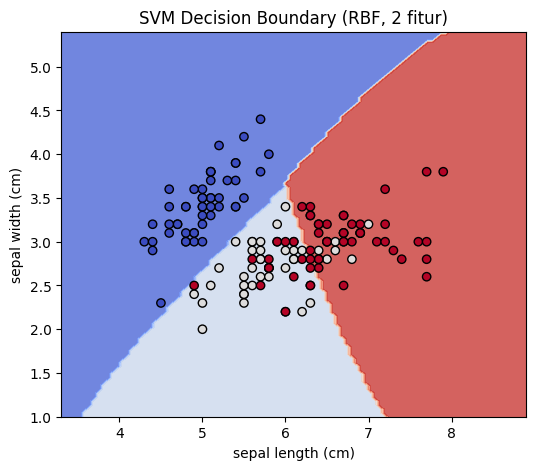

In [5]:
X2 = X[:, :2]
svm_2d = SVC(kernel="rbf").fit(X2, y)

fig, ax = plt.subplots(figsize=(6, 5))
DecisionBoundaryDisplay.from_estimator(
    svm_2d, X2, response_method="predict", plot_method="contourf",
    cmap=plt.cm.coolwarm, alpha=0.8, ax=ax)
ax.scatter(X2[:, 0], X2[:, 1], c=y, edgecolors="k", cmap=plt.cm.coolwarm)
ax.set_title("SVM Decision Boundary (RBF, 2 fitur)")
ax.set_xlabel(feature_names[0])
ax.set_ylabel(feature_names[1])
plt.show()

Plot ini memperlihatkan batas non-linear yang bisa dibentuk SVM lewat kernel trick. Batas sebenarnya dihitung di ruang berdimensi lebih tinggi, jadi gambar dua dimensi ini hanyalah versi "gepeng" dari ruang tersebut.

## 2. Kernel Functions and Their Applications

Fungsi kernel inilah yang memberi SVM kemampuan menangani data non-linear. Dengan memetakan data ke ruang berdimensi lebih tinggi, batas yang linear di ruang itu menjadi lengkung di ruang asal.

Analogi dari buku: akordeon. Saat terlipat, akordeon itu datar, seperti ruang fitur awal kita. Ketika ditarik, ia memanjang ke dimensi ketiga dan titik-titik data tersebar sepanjang dimensi baru itu. Di situ kita menemukan batas pemisah. Setelah akordeon dilipat lagi, batas lurus tadi ikut melengkung.

Tiga kernel yang dibahas:

- **Linear**: bentuk paling sederhana, untuk data yang sudah linear separable.
- **Polynomial**: memakai fungsi polinomial, berguna kalau hubungan antar fitur berbentuk polinomial.
- **RBF (radial basis function)**: memakai fungsi Gaussian. Salah satu kernel paling umum karena mampu menangani hubungan yang rumit.

Secara teknis, kernel trick menghitung perkalian dalam (dot product) di ruang berdimensi tinggi memakai data asli saja, tanpa benar-benar menghitung koordinat di ruang tersebut.

In [6]:
# Linear kernel sudah dicoba di atas; sekarang polynomial dan RBF
svm_poly = SVC(kernel="poly", degree=3).fit(X_train, y_train)
svm_rbf = SVC(kernel="rbf").fit(X_train, y_train)
svm_lin = SVC(kernel="linear").fit(X_train, y_train)

for name, m in [("Linear", svm_lin), ("Polynomial", svm_poly), ("RBF", svm_rbf)]:
    print(f"{name:<11} accuracy: {accuracy_score(y_test, m.predict(X_test)):.3f}")

Linear      accuracy: 0.933
Polynomial  accuracy: 0.956
RBF         accuracy: 0.911


In [7]:
y_pred_poly = svm_poly.predict(X_test)
print("Polynomial kernel")
display(styled_report(y_test, y_pred_poly, target_names=iris.target_names))

Polynomial kernel


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,1.000,0.833,0.909,12
virginica,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


In [8]:
y_pred_rbf = svm_rbf.predict(X_test)
print("RBF kernel")
display(styled_report(y_test, y_pred_rbf, target_names=iris.target_names))

RBF kernel


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.786,0.917,0.846,12
virginica,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


Di contoh buku, kernel polynomial sedikit lebih baik dari linear, sedangkan RBF paling rendah. Itu masih memakai semua argumen default. Setelah hyperparameter disetel (bagian 3), urutannya bisa berubah. Perbedaan kecil seperti ini penting di dunia nyata, karena selisih antara klasifikasi benar dan salah bisa berdampak besar bagi bisnis.

### Visualisasi Efek Kernel

Kita latih tiga SVM hanya dengan dua fitur, lalu bandingkan batas keputusannya.

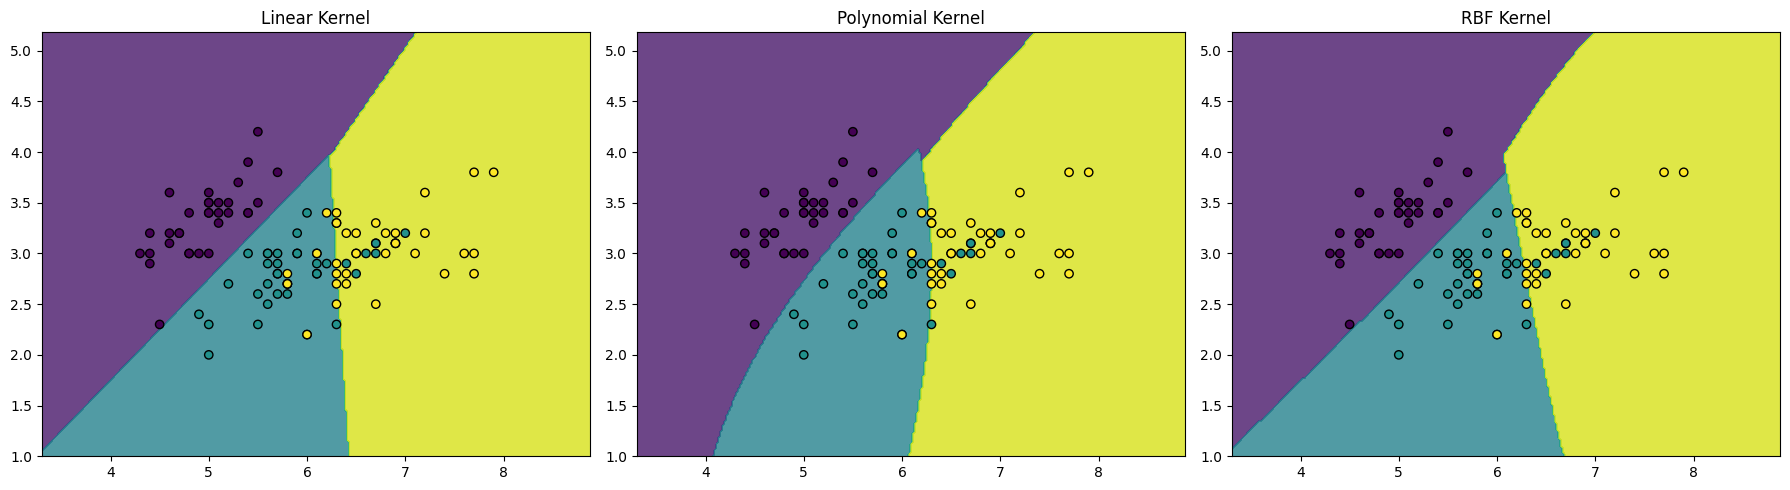

In [9]:
X_train_2d = X_train[:, :2]

models = {
    "Linear Kernel": SVC(kernel="linear").fit(X_train_2d, y_train),
    "Polynomial Kernel": SVC(kernel="poly").fit(X_train_2d, y_train),
    "RBF Kernel": SVC(kernel="rbf").fit(X_train_2d, y_train),
}

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, m) in zip(axes, models.items()):
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.8)
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors="k")
    ax.set_title(title)
plt.tight_layout()
plt.show()

Kernel linear menghasilkan batas lurus, sedangkan polynomial dan RBF menghasilkan batas yang lebih kompleks dan non-linear. Pada Iris dua fitur, perbedaannya tampak halus.

Selain tiga kernel tadi, ada kernel **sigmoid** untuk jenis data tertentu, dan kita juga bisa membuat **kernel kustom** untuk domain masalah yang khusus.

Untuk melihat manfaat kernel secara lebih jelas, berikut data berbentuk dua bulan sabit (`make_moons`) yang tidak mungkin dipisahkan garis lurus.

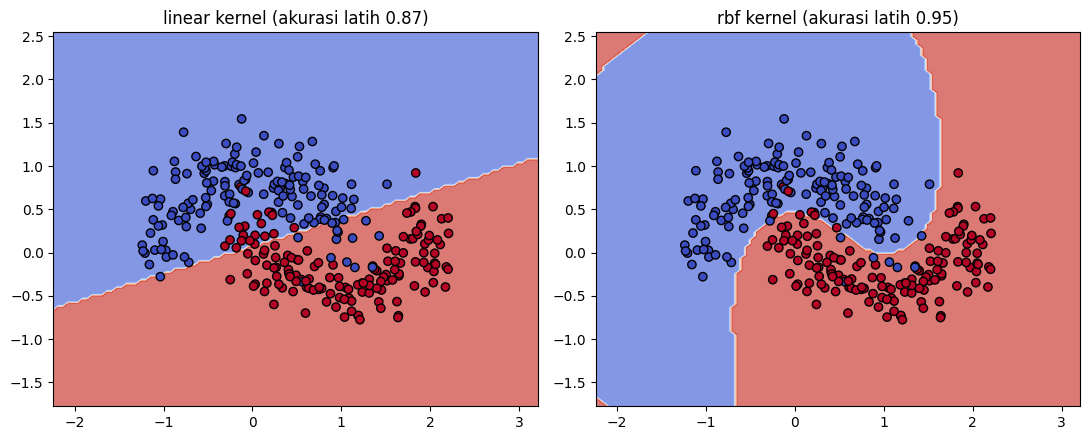

In [10]:
Xm, ym = make_moons(n_samples=300, noise=0.2, random_state=2024)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    m = SVC(kernel=kernel).fit(Xm, ym)
    DecisionBoundaryDisplay.from_estimator(
        m, Xm, response_method="predict", cmap=plt.cm.coolwarm, alpha=0.7, ax=ax)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, edgecolors="k", cmap=plt.cm.coolwarm)
    ax.set_title(f"{kernel} kernel (akurasi latih {m.score(Xm, ym):.2f})")
plt.tight_layout()
plt.show()

## 3. Tuning SVM Parameters

Seperti model lain, SVM bisa ditingkatkan lewat tuning hyperparameter. Kita pakai grid search dengan cross-validation. Parameter utama:

- **`C`** (regularisasi): mengatur trade-off antara margin lebar dan kesalahan klasifikasi. `C` besar berarti model kurang toleran terhadap salah klasifikasi.
- **`kernel`** dan parameternya: misalnya `degree` untuk polynomial dan `gamma` untuk RBF.

In [11]:
param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf", "poly"],
    "degree": [2, 3, 4],   # hanya dipakai kernel poly
}

grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.2f}")

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99


In [12]:
best_model = SVC(**grid_search.best_params_)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
display(styled_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.93


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.909,0.833,0.870,12
virginica,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


Hasilnya mirip dengan model tanpa tuning. Tuning tidak gagal di sini; datasetnya sendiri memang mudah diklasifikasi. Grid search bekerja dengan mencoba semua kombinasi parameter dan menilai tiap kombinasi dengan cross-validation, jadi makin banyak parameter yang dicoba, makin lama prosesnya. Alternatifnya adalah random search (`RandomizedSearchCV`) yang mencoba sebagian kombinasi secara acak dan lebih efisien untuk ruang parameter besar.

### Visualisasi Efek `C`

Kita jalankan grid search untuk kernel RBF dengan rentang `C` yang lebar, lalu plot skor cross-validation-nya.

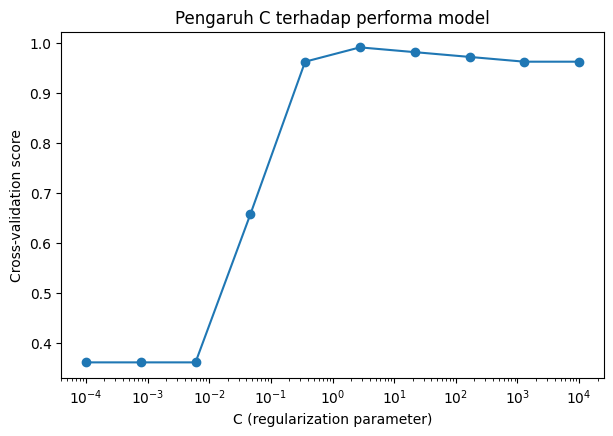

In [13]:
param_grid_c = {"C": np.logspace(-4, 4, 10), "kernel": ["rbf"]}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

plt.figure(figsize=(7, 4.5))
plt.plot(grid_search_c.cv_results_["param_C"].astype(float),
         grid_search_c.cv_results_["mean_test_score"], marker="o")
plt.xscale("log")
plt.xlabel("C (regularization parameter)")
plt.ylabel("Cross-validation score")
plt.title("Pengaruh C terhadap performa model")
plt.show()

Di contoh buku, performa mulai mendatar di sekitar C = 10, yaitu hasil tambahan yang semakin kecil dari menaikkan `C`. Perubahan yang tampak kecil pada metrik bisa tetap berarti besar dalam aplikasi nyata.

## 4. SVMs in High-Dimensional Spaces

SVM sering efektif pada data **berdimensi tinggi**, ketika jumlah fitur besar dibanding jumlah sampel (dataset "lebar"). Contohnya pengukuran peristiwa langka dengan banyak sensor yang masing-masing merekam ratusan nilai.

Kita buat data sintetis dengan 1000 fitur, yang hanya 50 di antaranya informatif.

In [14]:
Xh, yh = make_classification(
    n_samples=1000, n_features=1000, n_informative=50,
    n_redundant=0, random_state=2024)

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    Xh, yh, test_size=0.3, random_state=2024)

In [15]:
svm_high = SVC(kernel="linear")
svm_high.fit(Xh_train, yh_train)
yh_pred = svm_high.predict(Xh_test)

print(f"Accuracy: {accuracy_score(yh_test, yh_pred):.2f}")
display(styled_report(yh_test, yh_pred))

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


Dengan argumen bawaan, hasil di data berdimensi tinggi ini tidak sekuat yang diharapkan. Karena itu kita perlu tahu cara memperbaikinya: mencoba kernel lain dan menyetel `C` seperti pada bagian 3.

Pilihan kernel menyesuaikan sifat data:

- **Linear**: cocok untuk data yang linear separable atau saat jumlah fitur sangat besar.
- **Non-linear (RBF, polynomial)**: berguna kalau batas antar kelas rumit.

Regularisasi juga penting di ruang berdimensi tinggi untuk mencegah overfitting oleh fitur yang tidak relevan.

In [16]:
# Coba beberapa kernel dan nilai C pada data berdimensi tinggi
for kernel in ["linear", "rbf"]:
    for C in [0.1, 1, 10]:
        m = SVC(kernel=kernel, C=C).fit(Xh_train, yh_train)
        print(f"kernel={kernel:<6} C={C:<4} accuracy={m.score(Xh_test, yh_test):.3f}")

kernel=linear C=0.1  accuracy=0.747
kernel=linear C=1    accuracy=0.747
kernel=linear C=10   accuracy=0.747
kernel=rbf    C=0.1  accuracy=0.460
kernel=rbf    C=1    accuracy=0.883
kernel=rbf    C=10   accuracy=0.893


### Visualisasi Data Berdimensi Tinggi dengan PCA

Data seribu dimensi tidak bisa digambar langsung. PCA (dari Bab 3) memproyeksikannya ke dua dimensi sehingga strukturnya bisa dilihat kasar.

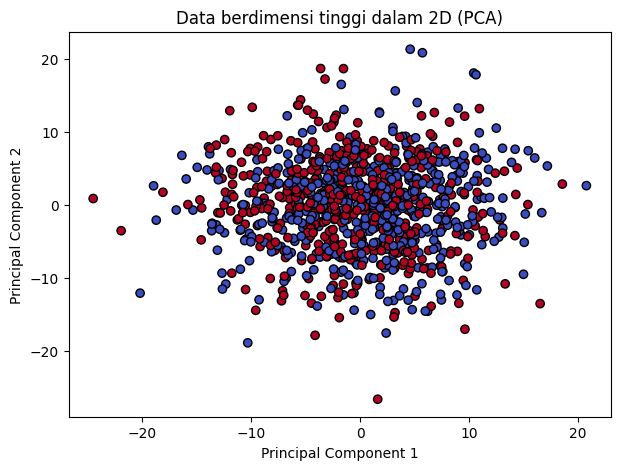

In [17]:
pca = PCA(n_components=2)
Xh_pca = pca.fit_transform(Xh)

plt.figure(figsize=(7, 5))
plt.scatter(Xh_pca[:, 0], Xh_pca[:, 1], c=yh, edgecolors="k", cmap="coolwarm")
plt.title("Data berdimensi tinggi dalam 2D (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

Setelah PCA dan pewarnaan per kelas, kelas-kelas masih sulit dipisahkan di dua komponen utama ini. Wajar, karena PCA hanya mengambil dua arah dengan variasi terbesar dan informasi pemisah kelas tersebar di banyak dimensi lain. Gambar ini memberi gambaran bahwa datanya berantakan, tetapi tidak berarti SVM di ruang aslinya tidak bisa memisahkan kelas.

## 5. Evaluating SVM Models

Evaluasi SVM memakai metrik yang sama dengan model klasifikasi lain: accuracy, precision, recall, F1, kurva ROC, dan AUC. Untuk menggambar kurva ROC kita butuh probabilitas, sehingga `SVC` harus dibuat dengan `probability=True` (probabilitas dihitung dengan cross-validation internal, jadi training jadi lebih lambat).

In [18]:
data = load_breast_cancer()
Xb, yb = data.data, data.target

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.3, random_state=2024)

svm_model = SVC(kernel="linear", probability=True)
svm_model.fit(Xb_train, yb_train)

yb_pred = svm_model.predict(Xb_test)
yb_prob = svm_model.predict_proba(Xb_test)[:, 1]

print(f"Accuracy: {accuracy_score(yb_test, yb_pred):.2f}")
display(styled_report(yb_test, yb_pred))

Accuracy: 0.95


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


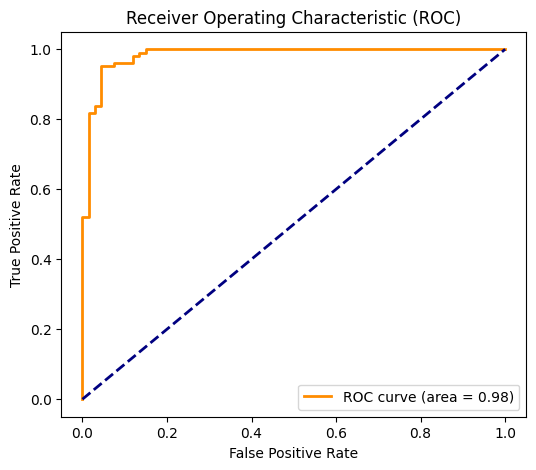

In [19]:
fpr, tpr, thresholds = roc_curve(yb_test, yb_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()

Hasil di Breast Cancer lebih kuat daripada contoh sebelumnya (AUC sekitar 0.98 di buku), sebagian karena kelasnya lebih mudah dipisahkan dan masalahnya biner, bukan tiga kelas seperti Iris.

Ringkasan metrik:

- **Accuracy**: proporsi prediksi benar.
- **Precision**: proporsi true positive di antara semua prediksi positif.
- **Recall**: proporsi true positive di antara semua kasus positif sebenarnya.
- **F1-score**: rata-rata harmonik precision dan recall.
- **ROC dan AUC**: performa di semua ambang, diringkas satu angka.

Kalau false positive mahal, utamakan precision. Kalau melewatkan kasus positif lebih berbahaya, utamakan recall.

## 6. Practical Exercises with SVMs

### Latihan 1: Membangun Classifier SVM Sederhana

Memakai dataset Iris.

In [20]:
iris = load_iris()
X_tr, X_te, y_tr, y_te = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=2024)

clf = SVC().fit(X_tr, y_tr)
pred = clf.predict(X_te)

print(f"Accuracy: {accuracy_score(y_te, pred):.3f}")
print(classification_report(y_te, pred, target_names=iris.target_names))

Accuracy: 0.911
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.79      0.92      0.85        12
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.90      0.91      0.90        45
weighted avg       0.92      0.91      0.91        45



### Latihan 2: Tuning Parameter SVM dengan Grid Search

Memakai dataset Breast Cancer. Karena SVM sensitif terhadap skala fitur, di sini ditambahkan `StandardScaler` dalam pipeline (hal ini tidak dilakukan di buku, tetapi praktik yang dianjurkan).

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    data.data, data.target, test_size=0.3, random_state=2024)

pipe = make_pipeline(StandardScaler(), SVC())
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__kernel": ["linear", "rbf"],
    "svc__gamma": ["scale", 0.01, 0.1],
}

gs = GridSearchCV(pipe, param_grid, cv=5)
gs.fit(Xb_tr, yb_tr)

print("Best params:", gs.best_params_)
print(f"Best CV score: {gs.best_score_:.3f}")

pred = gs.best_estimator_.predict(Xb_te)
print(f"Test accuracy: {accuracy_score(yb_te, pred):.3f}")
print(classification_report(yb_te, pred))

Best params: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best CV score: 0.977
Test accuracy: 0.982
              precision    recall  f1-score   support

           0       0.98      0.97      0.98        67
           1       0.98      0.99      0.99       104

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



### Latihan 3: Visualisasi Batas Keputusan SVM

Pada dataset biner sintetis dua fitur.

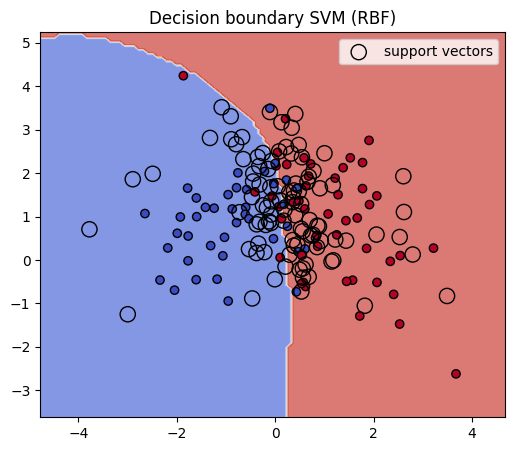

In [22]:
Xs, ys = make_classification(
    n_samples=300, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, class_sep=1.0, random_state=2024)

Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=2024)

clf = SVC(kernel="rbf", C=1.0).fit(Xs_tr, ys_tr)

fig, ax = plt.subplots(figsize=(6, 5))
DecisionBoundaryDisplay.from_estimator(
    clf, Xs, response_method="predict", cmap=plt.cm.coolwarm, alpha=0.7, ax=ax)
ax.scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, edgecolors="k", cmap=plt.cm.coolwarm)
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
           s=120, facecolors="none", edgecolors="k", label="support vectors")
ax.legend()
ax.set_title("Decision boundary SVM (RBF)")
plt.show()

## Poin-poin Penting Bab 7

- SVM mencari hyperplane dengan margin terlebar. Titik terdekat ke hyperplane disebut support vector, dan soft margin memungkinkan sebagian kesalahan agar model lebih tahan outlier.
- Kernel trick memungkinkan batas non-linear tanpa menghitung koordinat di ruang berdimensi tinggi. Tiga kernel utama: linear, polynomial, dan RBF.
- Parameter `C` mengatur trade-off margin dan kesalahan klasifikasi. Parameter kernel seperti `degree` dan `gamma` ikut menentukan hasil, dan semuanya disetel dengan grid search atau random search plus cross-validation.
- SVM kuat pada data berdimensi tinggi, tetapi dengan pengaturan bawaan hasilnya bisa mengecewakan, jadi kernel dan `C` perlu dicoba.
- Evaluasi memakai metrik klasifikasi yang sama. Untuk kurva ROC, `SVC` perlu `probability=True`. SVM sensitif terhadap skala fitur, jadi standardisasi biasanya membantu.

Referensi: Sukup, J. (2025). *scikit-learn Cookbook*, Third Edition, Bab 7 "Support Vector Machines and Kernel Methods". Packt Publishing.